<a href="https://colab.research.google.com/github/sagarsagat5360-svg/Smart-City-Traffic-Flow-Simulator/blob/main/smart_city_traffic_flow_simulator.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Smart City Traffic Flow Simulator

**Goal:** simulate 30 days of hourly vehicle counts for 10 city junctions (with morning and evening rush-hour peaks), then use NumPy aggregation to find the busiest hours and the junctions that become bottlenecks.

**Approach**

1. Build an hourly rush-hour curve (two Gaussian bumps around 08:00 and 18:00).
2. Simulate traffic with `np.random.poisson` into a 3-D array of shape `(days, junctions, hours)`.
3. Aggregate along different axes and find peak hours with `argmax`.
4. Flag bottlenecks (junction-hours above an assumed road capacity) and plot a heatmap.
5. Benchmark loop-based code against vectorized NumPy.

**Everything is simulated, so no data upload is needed.** Run it with *Runtime > Restart and run all*.

## 0. Setup

In [1]:
import os
import timeit

import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)  # fixed seed -> reproducible results
print("NumPy version:", np.__version__)

os.makedirs("images", exist_ok=True)  # figures are saved here

NumPy version: 2.1.3


## 1. The hourly rush-hour curve

Traffic is modelled as a quiet baseline of 100 vehicles/hour plus up to 300 extra vehicles at rush hour. Each rush hour is a Gaussian bump centred on 08:00 (morning) and 18:00 (evening).

03:00 -> expected  113.2 vehicles/hour
08:00 -> expected  400.0 vehicles/hour
13:00 -> expected  126.4 vehicles/hour
18:00 -> expected  400.0 vehicles/hour


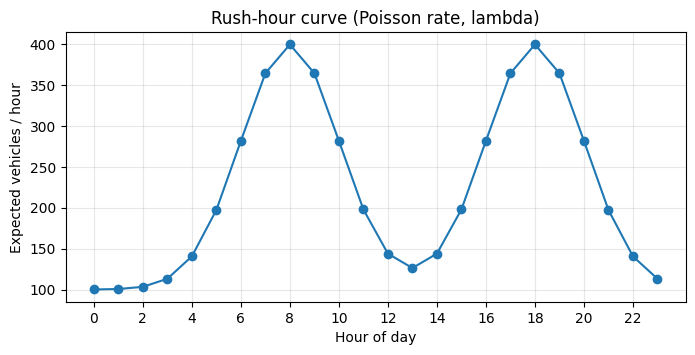

In [2]:
N_DAYS, N_JUNCTIONS, N_HOURS = 30, 10, 24

hours = np.arange(N_HOURS)
rush = np.exp(-(hours - 8) ** 2 / 8) + np.exp(-(hours - 18) ** 2 / 8)  # morning + evening bumps
base_lambda = 100 + 300 * rush  # expected vehicles/hour for an "average" junction, shape (24,)

for h in (3, 8, 13, 18):
    print(f"{h:02d}:00 -> expected {base_lambda[h]:6.1f} vehicles/hour")

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(hours, base_lambda, marker="o")
ax.set_xticks(range(0, 24, 2))
ax.set_xlabel("Hour of day")
ax.set_ylabel("Expected vehicles / hour")
ax.set_title("Rush-hour curve (Poisson rate, lambda)")
ax.grid(alpha=0.3)
plt.show()

## 2. Simulate traffic with `np.random.poisson`

Vehicle arrivals in a fixed time window are a classic Poisson process, so each junction-hour count is drawn from `Poisson(lambda)`.

To make the data interesting we scale `lambda` with **broadcasting**:

| Factor | Shape | Meaning |
|---|---|---|
| `day_factor` | `(30, 1, 1)` | weekends are 30% quieter |
| `junction_factor` | `(1, 10, 1)` | some junctions are busier by design |
| `base_lambda` | `(1, 1, 24)` | the rush-hour curve |

Multiplying them gives `lam` with shape `(30, 10, 24)`, i.e. `(days, junctions, hours)`.

In [3]:
day_of_week = np.arange(N_DAYS) % 7           # day 0 = Monday
is_weekend = day_of_week >= 5
day_factor = np.where(is_weekend, 0.70, 1.00)  # weekends are quieter
junction_factor = np.random.uniform(0.70, 1.50, N_JUNCTIONS)  # busier / quieter junctions

lam = (day_factor[:, None, None]
       * junction_factor[None, :, None]
       * base_lambda[None, None, :])           # broadcast -> (30, 10, 24)

data = np.random.poisson(lam, size=(N_DAYS, N_JUNCTIONS, N_HOURS))

print("shape (days, junctions, hours):", data.shape)
print("junction-hour records         :", data.size)
print("dtype                         :", data.dtype)
print("min / max vehicles in an hour :", data.min(), "/", data.max())

shape (days, junctions, hours): (30, 10, 24)
junction-hour records         : 7200
dtype                         : int64
min / max vehicles in an hour : 40 / 639


## 3. Aggregate by axis and find peak hours with `argmax`

The array axes are `0 = days`, `1 = junctions`, `2 = hours`. Passing a tuple to `axis=` collapses several axes at once.

Overall peak hour : 08:00  (410 vehicles/junction/hour)
Morning peak      : 08:00
Evening peak      : 18:00

Peak hour by junction: [18 18  8 18 18 18  8  8  8  8]

Average vehicles/junction/hour  weekday: 250.9  weekend: 176.5
Busiest day: day 19 (60,848 vehicles)  |  quietest day: day 14 (41,702 vehicles)


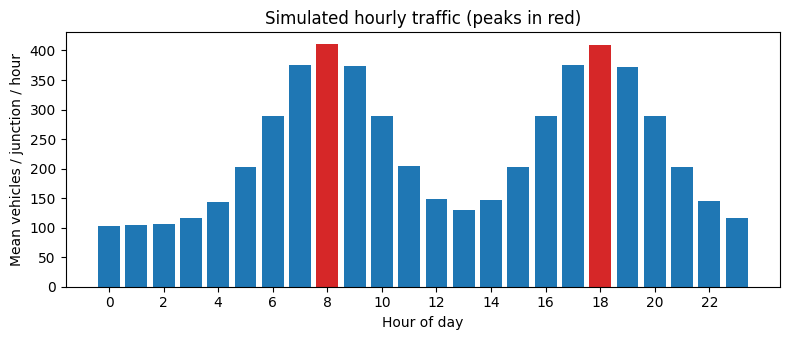

In [4]:
hourly_mean = data.mean(axis=(0, 1))    # (24,) average over days and junctions
junction_mean = data.mean(axis=(0, 2))  # (10,) average over days and hours
daily_total = data.sum(axis=(1, 2))     # (30,) city-wide vehicles per day

peak_hour = hourly_mean.argmax()
am_peak = hourly_mean[:12].argmax()
pm_peak = 12 + hourly_mean[12:].argmax()
print(f"Overall peak hour : {peak_hour:02d}:00  ({hourly_mean[peak_hour]:.0f} vehicles/junction/hour)")
print(f"Morning peak      : {am_peak:02d}:00")
print(f"Evening peak      : {pm_peak:02d}:00")

# Peak hour for every junction separately
profile = data.mean(axis=0)                  # (10, 24) average day for each junction
peak_by_junction = profile.argmax(axis=1)    # (10,)
print("\nPeak hour by junction:", peak_by_junction)

# Weekday vs weekend with a boolean mask along the days axis
print(f"\nAverage vehicles/junction/hour  weekday: {data[~is_weekend].mean():.1f}  weekend: {data[is_weekend].mean():.1f}")
print(f"Busiest day: day {daily_total.argmax() + 1} ({daily_total.max():,} vehicles)  |  quietest day: day {daily_total.argmin() + 1} ({daily_total.min():,} vehicles)")

fig, ax = plt.subplots(figsize=(8, 3.5))
colors = ["tab:red" if h in (am_peak, pm_peak) else "tab:blue" for h in hours]
ax.bar(hours, hourly_mean, color=colors)
ax.set_xticks(range(0, 24, 2))
ax.set_xlabel("Hour of day")
ax.set_ylabel("Mean vehicles / junction / hour")
ax.set_title("Simulated hourly traffic (peaks in red)")
plt.tight_layout()
plt.savefig("images/hourly_profile.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Find the bottlenecks

A **bottleneck** is a junction that regularly carries more traffic than the road can handle. We assume a capacity of **450 vehicles/hour** (change `CAPACITY` to experiment) and count how many junction-hours go over it.

Rank  Junction  Congested hrs  % of hours  Mean veh/hr
   1  J2                 133       18.5%        302.7
   2  J8                 131       18.2%        288.3
   3  J3                 115       16.0%        266.2
   4  J10                110       15.3%        262.0
   5  J4                  49        6.8%        244.5
   6  J9                  48        6.7%        244.5
   7  J1                   1        0.1%        206.6
   8  J5                   0        0.0%        171.0
   9  J7                   0        0.0%        154.3
  10  J6                   0        0.0%        170.9

Top 3 bottlenecks: J2, J8, J3
Share of all junction-hours over capacity: 8.2%


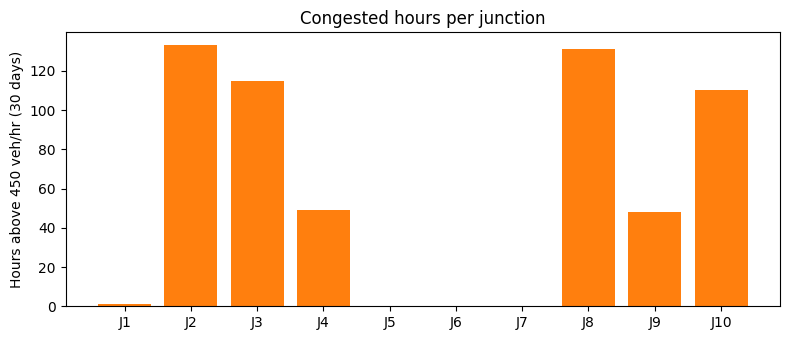

In [5]:
CAPACITY = 450  # assumed vehicles/hour a junction can handle

over_capacity = data > CAPACITY                     # boolean array, (30, 10, 24)
congested_hours = over_capacity.sum(axis=(0, 2))    # (10,) congested hours per junction
congestion_rate = 100 * congested_hours / (N_DAYS * N_HOURS)
ranking = np.argsort(-congested_hours)              # worst junction first

print("Rank  Junction  Congested hrs  % of hours  Mean veh/hr")
for rank, j in enumerate(ranking, start=1):
    print(f"{rank:>4}  J{j + 1:<7} {congested_hours[j]:>13} {congestion_rate[j]:>10.1f}% {junction_mean[j]:>12.1f}")

top3 = ranking[:3] + 1
print(f"\nTop 3 bottlenecks: J{top3[0]}, J{top3[1]}, J{top3[2]}")
print(f"Share of all junction-hours over capacity: {100 * over_capacity.mean():.1f}%")

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar([f"J{j + 1}" for j in range(N_JUNCTIONS)], congested_hours, color="tab:orange")
ax.set_ylabel(f"Hours above {CAPACITY} veh/hr (30 days)")
ax.set_title("Congested hours per junction")
plt.tight_layout()
plt.savefig("images/bottlenecks.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Heatmap: junction x hour

Each cell is the average vehicle count for one junction at one hour of the day. The two bright vertical bands are the morning and evening rush hours; bright rows are the bottleneck junctions.

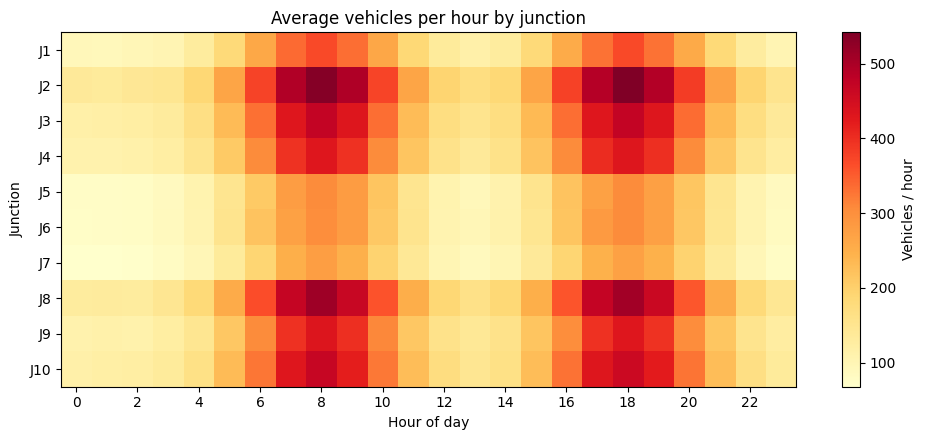

In [6]:
fig, ax = plt.subplots(figsize=(10, 4.5))
im = ax.imshow(profile, aspect="auto", cmap="YlOrRd")
ax.set_xticks(range(0, 24, 2))
ax.set_yticks(range(N_JUNCTIONS))
ax.set_yticklabels([f"J{j + 1}" for j in range(N_JUNCTIONS)])
ax.set_xlabel("Hour of day")
ax.set_ylabel("Junction")
ax.set_title("Average vehicles per hour by junction")
fig.colorbar(im, ax=ax, label="Vehicles / hour")
plt.tight_layout()
plt.savefig("images/heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Benchmark: Python loops vs vectorized NumPy

We time the same two jobs written both ways: averaging over days and junctions for every hour, and generating the Poisson data itself. In a notebook cell you can also use the `%timeit` magic, for example `%timeit data.mean(axis=(0, 1))`. Here we use the `timeit` module so the results can be stored and reused in the summary.

In [7]:
def hourly_mean_loop(arr):
    d, j, h = arr.shape
    out = np.zeros(h)
    for hr in range(h):
        total = 0
        for day in range(d):
            for jn in range(j):
                total += arr[day, jn, hr]
        out[hr] = total / (d * j)
    return out


def simulate_loop():
    out = np.empty((N_DAYS, N_JUNCTIONS, N_HOURS), dtype=np.int64)
    for d in range(N_DAYS):
        for j in range(N_JUNCTIONS):
            for h in range(N_HOURS):
                out[d, j, h] = np.random.poisson(lam[d, j, h])
    return out


def simulate_vectorized():
    return np.random.poisson(lam, size=lam.shape)


def best_time(fn, number, repeat=5):
    # best of `repeat` runs, in seconds per call
    return min(timeit.repeat(fn, number=number, repeat=repeat)) / number


# Correctness first: both aggregation methods must agree
assert np.allclose(hourly_mean_loop(data), hourly_mean)

t_agg_loop = best_time(lambda: hourly_mean_loop(data), number=20)
t_agg_vec = best_time(lambda: data.mean(axis=(0, 1)), number=2000)
t_sim_loop = best_time(simulate_loop, number=5)
t_sim_vec = best_time(simulate_vectorized, number=200)

speedup_agg = t_agg_loop / t_agg_vec
speedup_sim = t_sim_loop / t_sim_vec

print(f"{'Task':<28}{'Loop':>12}{'Vectorized':>14}{'Speedup':>10}")
print(f"{'Aggregate (mean per hour)':<28}{t_agg_loop * 1e3:>10.3f}ms{t_agg_vec * 1e6:>11.1f}us{speedup_agg:>9.0f}x")
print(f"{'Simulate (Poisson draws)':<28}{t_sim_loop * 1e3:>10.3f}ms{t_sim_vec * 1e6:>11.1f}us{speedup_sim:>9.0f}x")

Task                                Loop    Vectorized   Speedup
Aggregate (mean per hour)        1.639ms       38.3us       43x
Simulate (Poisson draws)        30.372ms     1388.7us       22x


## 7. Results summary

These are the numbers to quote in your README and on your resume. The traffic results are seeded, so they are identical on every run; the speedups depend on the Colab machine, so use the values from your own run.

In [8]:
print("=== RESULTS SUMMARY ===")
print(f"Junction-hour records simulated : {data.size:,}  ({N_DAYS} days x {N_JUNCTIONS} junctions x {N_HOURS} hours)")
print(f"Morning / evening peak          : {am_peak:02d}:00 / {pm_peak:02d}:00")
print(f"Top 3 bottleneck junctions      : J{top3[0]}, J{top3[1]}, J{top3[2]}")
print(f"Junction-hours over {CAPACITY} veh/hr  : {100 * over_capacity.mean():.1f}%")
print(f"Vectorized speedup (aggregation): {speedup_agg:.0f}x")
print(f"Vectorized speedup (simulation) : {speedup_sim:.0f}x")

=== RESULTS SUMMARY ===
Junction-hour records simulated : 7,200  (30 days x 10 junctions x 24 hours)
Morning / evening peak          : 08:00 / 18:00
Top 3 bottleneck junctions      : J2, J8, J3
Junction-hours over 450 veh/hr  : 8.2%
Vectorized speedup (aggregation): 43x
Vectorized speedup (simulation) : 22x


## Conclusions and next steps

* Rush-hour peaks appear exactly where the model puts them (08:00 and 18:00), and a handful of junctions account for most of the congestion.
* Vectorized NumPy is orders of magnitude faster than the equivalent nested Python loops, with identical results.

**Ideas to extend this project**

* Replace the fixed `CAPACITY` with a per-junction capacity.
* Add an incident (accident or road closure) on one junction and measure the effect on its neighbours.
* Switch to the modern `np.random.default_rng(42)` generator.
* Fit the simulated data with a simple forecasting model.